# EcoData · S10 — Series de tiempo e inferencia en streaming
**Lanzeloth Vargas Marichi** · Proyecto Sello EcoData · Big Data, UPeU

La guía predice `CE(t+1)` con `lead()`, compara contra **persistencia** y aplica el modelo en vivo sin estado. En EcoData la variable es **PM2.5 a +1 hora** (Juliaca):

| Guía S10 | EcoData |
|---|---|
| Gold de S04 (`campo_electrico_particionado`) | histórico real de Open-Meteo/CAMS de Juliaca (`aq_juliaca_2023.json`) |
| `label = lead("CE", 1)` | `label = lead("pm25", 1)`, verificando que la hora siguiente es consecutiva |
| 8 variables del mismo instante | `pm25`, `pm10` y la **hora del día** (seno/coseno), calculadas **dentro del Pipeline** |
| productor `campo-electrico-eventos` | topic **`ecodata-s10-aire`**, horas reales de la **cola del conjunto de prueba** publicadas a ritmo controlado |
| inferencia sin estado | idéntica: una lectura basta; no hay ventanas ni watermark |

> **Relación con el modelo de producción (S12):** el modelo que alimenta Grafana usa 24 h de historial y predice el *delta* (MAE 0,446 vs 0,587 de persistencia, +24,1 %). Éste de S10 es **más simple a propósito** (sin estado), para cumplir la mecánica de la guía y comparar con honestidad. El resultado puede ser mejor o peor que persistencia: se reporta tal cual.
>
> **Transparencia:** el «stream» es el reenvío de horas reales de prueba (`origen = openmeteo-replay`), una cada 3 s. Cierra otros cuadernos de Spark antes de ejecutar.

## 0. Preparación y SparkSession

In [1]:
import sys, json, time, threading, urllib.request, urllib.parse, os
from datetime import datetime, timezone
import pandas as pd
sys.path.insert(0, "/tmp/s12/scripts")
import aire_comun as aire
import openmeteo_a_kafka as pub_aire
from kafka import KafkaProducer, KafkaConsumer, TopicPartition
from kafka.admin import KafkaAdminClient, NewTopic
from kafka.errors import TopicAlreadyExistsError

BOOTSTRAP = "kafka:9092"
PUSHGATEWAY = "http://pushgateway:9091"
PROMETHEUS_CANDIDATOS = ["http://prometheus:9090", "http://lambda26-prometheus:9090"]
PKG = "org.apache.spark:spark-sql-kafka-0-10_2.13:4.2.0"

def crear_topic(nombre, particiones=3):
    adm = KafkaAdminClient(bootstrap_servers=BOOTSTRAP)
    try: adm.create_topics([NewTopic(nombre, num_partitions=particiones, replication_factor=1)]); print("topic creado:", nombre)
    except TopicAlreadyExistsError: print("el topic ya existía:", nombre)
    adm.close()

def prom(q):
    for base in PROMETHEUS_CANDIDATOS:
        try:
            u = f"{base}/api/v1/query?" + urllib.parse.urlencode({"query": q})
            return json.load(urllib.request.urlopen(u, timeout=4))["data"]["result"]
        except Exception:
            continue
    return None

def publicar_paced(topic, eventos, pausa_s=2.0):
    """Publica un evento cada pausa_s segundos en segundo plano (la celda no se bloquea)."""
    def run():
        p = KafkaProducer(bootstrap_servers=BOOTSTRAP, acks="all", key_serializer=str.encode,
                          value_serializer=lambda v: json.dumps(v).encode())
        for e in eventos:
            p.send(topic, key=e["sensorId"], value=e); p.flush(); time.sleep(pausa_s)
        p.close()
    th = threading.Thread(target=run, daemon=True); th.start(); return th

def desde_archivo(path="/tmp/s12/aq_juliaca_2023.json"):
    d = json.load(open(path)); h = d.get("hourly", d); out = []
    for t, a, b in zip(h["time"], h["pm2_5"], h["pm10"]):
        if a is None: continue
        ts = int(datetime.fromisoformat(t).replace(tzinfo=timezone.utc).timestamp() * 1000)
        out.append((ts, float(a), float(b) if b is not None else float(a)))
    return out

TOPIC = "ecodata-s10-aire"
crear_topic(TOPIC)

topic creado: ecodata-s10-aire


In [2]:
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import StructType, StringType, DoubleType, LongType
esquema_evento = (StructType().add("tipoEvento", StringType()).add("sensorId", StringType())
                  .add("pm25", DoubleType()).add("pm10", DoubleType())
                  .add("origen", StringType()).add("timestamp", LongType()))
spark = (SparkSession.builder.appName("ecodata-s10").master("local[2]")
         .config("spark.jars.packages", PKG)
         .config("spark.sql.shuffle.partitions", "3")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.ui.port", "4051")          # distinto del 4040 que usan los jobs de S12
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)
from pyspark.sql.window import Window
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import VectorAssembler, SQLTransformer
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

:: loading settings :: url = jar:file:/usr/local/lib/python3.10/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
org.apache.spark#spark-sql-kafka-0-10_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-4e86d597-8346-4042-9dfb-dab8746175ca;1.0
	confs: [default]
	found org.apache.spark#spark-sql-kafka-0-10_2.13;4.2.0 in spark-list
	found org.apache.spark#spark-token-provider-kafka-0-10_2.13;4.2.0 in central
	found org.apache.kafka#kafka-clients;3.9.2 in central
	found at.yawk.lz4#lz4-java;1.11.0 in central
	found org.xerial.snappy#snappy-java;1.1.10.8 in central
	found org.slf4j#slf4j-api;2.0.17 in central
	found org.apache.hadoop#hadoop-client-runtime;3.5.0 in central
	found org.apache.hadoop#hadoop-client-api;3.5.0 in central
	found com.google.code.findbugs#jsr305;3.0.0 in central
	found org.scala-lang.

Spark 4.2.0


## 1. Business Understanding (3.1.2)
**Objetivo:** estimar el PM2.5 de la **hora siguiente** (`label = PM2.5 en t+1`) a partir de la lectura actual (PM2.5, PM10 y hora del día).
**Alcance:** comparar persistencia, LinearRegression, RandomForest y GBT con división cronológica y RMSE/MAE/R², y aplicar el ganador en tiempo real.

## 2. Dataset supervisado con `lead()` y división cronológica (3.2–3.3)

In [3]:
filas = desde_archivo()
df = spark.createDataFrame(filas, ["timestamp", "pm25", "pm10"])
orden = Window.orderBy("timestamp")
ds = (df.withColumn("label", F.lead("pm25", 1).over(orden))
        .withColumn("ts_sig", F.lead("timestamp", 1).over(orden)))
total = ds.count()
ds = ds.na.drop().filter(F.col("ts_sig") - F.col("timestamp") == 3600_000).drop("ts_sig")   # solo horas consecutivas
print(f"Filas históricas: {total:,} · filas del dataset supervisado: {ds.count():,} (se descartan la última y cualquier hueco)")
ds.orderBy("timestamp").show(5)

Filas históricas: 8,760 · filas del dataset supervisado: 8,759 (se descartan la última y cualquier hueco)
+-------------+----+----+-----+
|    timestamp|pm25|pm10|label|
+-------------+----+----+-----+
|1672531200000| 0.0| 0.0|  0.2|
|1672534800000| 0.2| 0.3|  0.4|
|1672538400000| 0.4| 0.5|  0.3|
|1672542000000| 0.3| 0.4|  0.3|
|1672545600000| 0.3| 0.4|  0.3|
+-------------+----+----+-----+
only showing top 5 rows


In [4]:
num = ds.withColumn("n", F.row_number().over(orden))
corte = int(num.count() * 0.80)
train = num.filter(F.col("n") <= corte).drop("n"); test = num.filter(F.col("n") > corte).drop("n")
fmax_train = train.agg(F.max("timestamp")).first()[0]; fmin_test = test.agg(F.min("timestamp")).first()[0]
assert fmax_train < fmin_test, "La división no respeta el orden cronológico"
f = lambda ms: pd.to_datetime(ms, unit="ms")
print(f"Entrenamiento: {train.count():,} filas (hasta {f(fmax_train)} UTC)")
print(f"Prueba:        {test.count():,} filas (desde {f(fmin_test)} UTC) → sin fuga de información")

Entrenamiento: 7,007 filas (hasta 2023-10-19 22:00:00 UTC)
Prueba:        1,752 filas (desde 2023-10-19 23:00:00 UTC) → sin fuga de información


## 3. Baseline de persistencia, calculado ANTES de entrenar (3.4.1)
`PM2.5(t+1) = PM2.5(t)`: es lo que hay que superar (caso M4 de la guía).

In [5]:
ev = {m: RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName=m) for m in ("rmse", "mae", "r2")}
def evaluar(pred, nombre):
    r = {"Modelo": nombre, "RMSE": ev["rmse"].evaluate(pred), "MAE": ev["mae"].evaluate(pred), "R2": ev["r2"].evaluate(pred)}
    print(f"{nombre}: RMSE={r['RMSE']:.4f}  MAE={r['MAE']:.4f}  R2={r['R2']:.4f}"); return r
res_pers = evaluar(test.withColumn("prediction", F.col("pm25")), "Persistencia (PM2.5_t+1 = PM2.5_t)")

Persistencia (PM2.5_t+1 = PM2.5_t): RMSE=1.5047  MAE=0.6861  R2=0.8478


## 4. Modelado comparado (3.4.2–3.5.1)
La hora del día se calcula **dentro del Pipeline** (`SQLTransformer`), de modo que en producción el modelo solo necesita las columnas del evento.

In [6]:
HORA = SQLTransformer(statement="""SELECT *,
    sin(2 * pi() * hour(CAST(`timestamp` / 1000 AS TIMESTAMP)) / 24) AS h_sin,
    cos(2 * pi() * hour(CAST(`timestamp` / 1000 AS TIMESTAMP)) / 24) AS h_cos FROM __THIS__""")
ENS = VectorAssembler(inputCols=["pm25", "pm10", "h_sin", "h_cos"], outputCol="features")
candidatos = {
    "LinearRegression": LinearRegression(featuresCol="features", labelCol="label"),
    "RandomForestRegressor": RandomForestRegressor(featuresCol="features", labelCol="label", numTrees=50, maxDepth=8, seed=42),
    "GBTRegressor": GBTRegressor(featuresCol="features", labelCol="label", maxIter=40, maxDepth=5, seed=42),
}
modelos, resultados = {}, [res_pers]
for nombre, est in candidatos.items():
    m = Pipeline(stages=[HORA, ENS, est]).fit(train); modelos[nombre] = m
    resultados.append(evaluar(m.transform(test), nombre))
comp = pd.DataFrame(resultados)
comp["Mejora RMSE vs persistencia %"] = 100 * (res_pers["RMSE"] - comp["RMSE"]) / res_pers["RMSE"]
comp["Mejora MAE vs persistencia %"] = 100 * (res_pers["MAE"] - comp["MAE"]) / res_pers["MAE"]
comp.round(4)

netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory
netlib-lapack: JNI_OnLoad: dlopen(liblapack.so.3) failed: liblapack.so.3: cannot open shared object file: No such file or directory


LinearRegression: RMSE=1.4294  MAE=0.7331  R2=0.8627
RandomForestRegressor: RMSE=1.5395  MAE=0.7833  R2=0.8407
GBTRegressor: RMSE=1.4877  MAE=0.7465  R2=0.8513


,Modelo,RMSE,MAE,R2,Mejora RMSE vs persistencia %,Mejora MAE vs persistencia %
0,Persistencia (PM2.5_t+1 = PM2.5_t),1.5047,0.6861,0.8478,0.0000,0.0000
1,LinearRegression,1.4294,0.7331,0.8627,5.0044,-6.8541
2,RandomForestRegressor,1.5395,0.7833,0.8407,-2.3089,-14.1722
3,GBTRegressor,1.4877,0.7465,0.8513,1.1329,-8.8147


## 5. Selección honesta (3.5.2)

In [7]:
mej = comp.iloc[1:].sort_values("RMSE").iloc[0]
ganador = mej["Modelo"]; margen = mej["Mejora RMSE vs persistencia %"]; margen_mae = mej["Mejora MAE vs persistencia %"]
print(f"Mejor modelo por RMSE: {ganador} · mejora de RMSE vs persistencia: {margen:+.2f} % · de MAE: {margen_mae:+.2f} %")
if margen <= 0:
    print("LECTURA: ningún modelo superó a la persistencia en RMSE → no se justifica desplegar; se guarda igual para la infraestructura (como pide la guía).")
elif margen < 3:
    print("LECTURA: el margen es mínimo → probablemente no justifica el costo de mantener un modelo entrenado; su valor está en la infraestructura de inferencia.")
else:
    print("LECTURA: el margen es apreciable → el modelo se justifica frente a la persistencia, con la salvedad de validar el error en producción (Regla #37, S11).")

Mejor modelo por RMSE: LinearRegression · mejora de RMSE vs persistencia: +5.00 % · de MAE: -6.85 %
LECTURA: el margen es apreciable → el modelo se justifica frente a la persistencia, con la salvedad de validar el error en producción (Regla #37, S11).


## 6. Guardar y recargar el PipelineModel (3.6.1)
Se guarda el **Pipeline completo** (hora del día + ensamblado + modelo) y se verifica que recargado predice lo mismo.

In [8]:
RUTA_MODELO = "./artifacts/models/modelo_pm25_s10"
modelos[ganador].write().overwrite().save(RUTA_MODELO)
cargado = PipelineModel.load(RUTA_MODELO)
a = modelos[ganador].transform(test).select("timestamp", F.col("prediction").alias("antes"))
b = cargado.transform(test).select("timestamp", F.col("prediction").alias("despues"))
dif = a.join(b, "timestamp").agg(F.max(F.abs(F.col("antes") - F.col("despues")))).first()[0]
print("Modelo guardado y recargado en:", RUTA_MODELO)
print("Diferencia máxima entre predicciones antes/después de recargar:", dif)
assert dif < 1e-9

Modelo guardado y recargado en: ./artifacts/models/modelo_pm25_s10
Diferencia máxima entre predicciones antes/después de recargar: 0.0


## 7. Inferencia en tiempo real, sin estado (3.7)
Se publican, a ritmo controlado, las últimas 40 horas **reales del conjunto de prueba**; el modelo recargado predice cada lectura tal como llega (sin ventanas ni watermark), y como las horas son consecutivas, la predicción de cada lectura se puede comparar con la hora real siguiente.

In [9]:
crudo = (spark.readStream.format("kafka").option("kafka.bootstrap.servers", BOOTSTRAP)
         .option("subscribe", "ecodata-s10-aire").option("startingOffsets", "latest").option("failOnDataLoss", "false").load())
eventos = (crudo.select("topic", "partition", "offset", F.col("timestamp").alias("kafkaTimestamp"),
                        F.from_json(F.col("value").cast("string"), esquema_evento).alias("e"))
           .select("topic", "partition", "offset", "kafkaTimestamp", "e.*"))
predicciones_stream = cargado.transform(eventos)          # el Pipeline guardado hace todo el trabajo
RUTA_PRED = "./artifacts/s10_predicciones_stream"; CHK_PRED = "./artifacts/chk_s10"
captura = []
def guardar(dfm, bid):
    n = dfm.count()
    if n == 0:
        captura.append(dict(batchId=bid, filas=0)); return
    out = dfm.select(F.lit(bid).alias("batchId"), "sensorId", "timestamp", "pm25", F.col("prediction").alias("pred_pm25_siguiente"))
    out.write.mode("append").parquet(RUTA_PRED)
    for r in out.collect(): captura.append({**r.asDict(), "filas": n})

if "q" in dir() and q.isActive: q.stop()
q = predicciones_stream.writeStream.foreachBatch(guardar).option("checkpointLocation", CHK_PRED).start()
print("consulta activa:", q.isActive)

consulta activa: True


In [10]:
cola = test.orderBy(F.desc("timestamp")).limit(40).orderBy("timestamp").select("timestamp", "pm25", "pm10").collect()
eventos_pub = [aire.evento(r["timestamp"], r["pm25"], r["pm10"], "openmeteo-replay") for r in cola]
h = publicar_paced(TOPIC, eventos_pub, pausa_s=3.0)
print(len(eventos_pub), "eventos publicados a razón de 1 cada 3 s (≈ 2 min)")

40 eventos publicados a razón de 1 cada 3 s (≈ 2 min)


In [11]:
time.sleep(5)
print("micro-lotes con datos hasta ahora:", len([c for c in captura if c.get("filas")]))
for c in captura[-5:]: print(c)          # repite esta celda mientras corre la publicación

micro-lotes con datos hasta ahora: 4
{'batchId': 0, 'filas': 0}
{'batchId': 1, 'sensorId': 'openmeteo-cams-juliaca', 'timestamp': 1703919600000, 'pm25': 9.7, 'pred_pm25_siguiente': 9.18317002502338, 'filas': 1}
{'batchId': 2, 'sensorId': 'openmeteo-cams-juliaca', 'timestamp': 1703923200000, 'pm25': 9.5, 'pred_pm25_siguiente': 8.894239866015884, 'filas': 1}
{'batchId': 3, 'sensorId': 'openmeteo-cams-juliaca', 'timestamp': 1703926800000, 'pm25': 9.1, 'pred_pm25_siguiente': 8.438248370079677, 'filas': 1}
{'batchId': 4, 'sensorId': 'openmeteo-cams-juliaca', 'timestamp': 1703930400000, 'pm25': 7.5, 'pred_pm25_siguiente': 6.911043641091651, 'filas': 1}


In [12]:
h.join(timeout=180); time.sleep(10)
q.stop()
res = spark.read.parquet(RUTA_PRED).orderBy("timestamp").toPandas()
res["pm25_real_siguiente"] = res["pm25"].shift(-1)
aud = res.dropna()
mae_prod = (aud["pred_pm25_siguiente"] - aud["pm25_real_siguiente"]).abs().mean()
mae_pers = (aud["pm25"] - aud["pm25_real_siguiente"]).abs().mean()
print(f"Predicciones capturadas: {len(res)} · comparables: {len(aud)}")
print(f"MAE del modelo en el stream: {mae_prod:.4f} µg/m³ · MAE de persistencia en las mismas horas: {mae_pers:.4f} µg/m³")
res.head(8)

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


Predicciones capturadas: 40 · comparables: 39
MAE del modelo en el stream: 0.5975 µg/m³ · MAE de persistencia en las mismas horas: 0.6308 µg/m³


,batchId,sensorId,timestamp,pm25,pred_pm25_siguiente,pm25_real_siguiente
0,1,openmeteo-cams-juliaca,1703919600000,9.7,9.183170,9.5
1,2,openmeteo-cams-juliaca,1703923200000,9.5,8.894240,9.1
2,3,openmeteo-cams-juliaca,1703926800000,9.1,8.438248,7.5
3,4,openmeteo-cams-juliaca,1703930400000,7.5,6.911044,5.8
4,5,openmeteo-cams-juliaca,1703934000000,5.8,5.318235,5.5
5,6,openmeteo-cams-juliaca,1703937600000,5.5,5.028382,3.7
6,7,openmeteo-cams-juliaca,1703941200000,3.7,3.402966,2.4
7,8,openmeteo-cams-juliaca,1703944800000,2.4,2.261555,2.5


Text(0, 0.5, 'µg/m³')

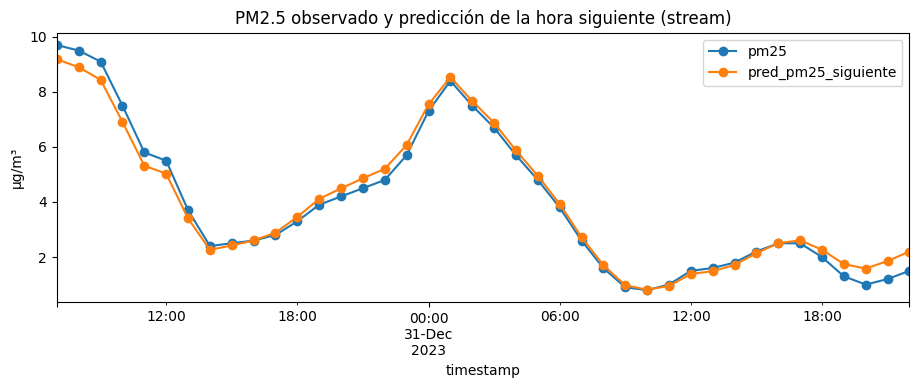

In [13]:
ax = res.set_index(pd.to_datetime(res.timestamp, unit="ms"))[["pm25", "pred_pm25_siguiente"]].plot(
        figsize=(11, 3.5), marker="o", title="PM2.5 observado y predicción de la hora siguiente (stream)")
ax.set_ylabel("µg/m³")

## 8. Hallazgo para el informe
Escribe un error o hallazgo **real** de tu ejecución. Candidatos que suelen aparecer: (a) `Micro-lote 0: sin filas` (no es un error); (b) horas no consecutivas descartadas al construir `label`; (c) el modelo que «gana» por un margen mínimo o pierde frente a persistencia (caso M4); (d) `hour()` dependiente de la zona horaria: por eso `spark.sql.session.timeZone = UTC`.

### Qué capturar (con **reloj del sistema y tu perfil visibles**)
1. Sección 2: `lead()`, conteos y división cronológica con fechas.
2. Sección 3: baseline. Sección 4: tabla comparativa. Sección 5: selección.
3. Sección 6: guardado/recarga y diferencia ≈ 0.
4. Sección 7: bitácora del stream, tabla de predicciones y MAE; Kafka UI → `ecodata-s10-aire`.

In [14]:
spark.stop()